==========================================================

MOVING AVERAGE FORECASTING

==========================================================

What is Moving Average?

-----------------------
Moving Average is one of the simplest time series forecasting methods.
It predicts future values by calculating the average of the last 'n'
observations.

Formula:
Y(t-1) + Y(t-2) + ... + Y(t-n)
Forecast = ------------------------------
n

where,
Y = Actual value
n = Window size
Example:

Last 3 sales = 100, 120, 140
Forecast =
(100 + 120 + 140) / 3
= 120

==========================================================

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
sales = [100, 120, 110, 130, 150,
         170, 160, 180, 200, 190]

months = ["Jan", "Feb", "Mar", "Apr", "May",
          "Jun", "Jul", "Aug", "Sep", "Oct"]

In [9]:
df=pd.DataFrame({"Months":months,
                 "Sales":sales})
print("Original Data")
print(df)

Original Data
  Months  Sales
0    Jan    100
1    Feb    120
2    Mar    110
3    Apr    130
4    May    150
5    Jun    170
6    Jul    160
7    Aug    180
8    Sep    200
9    Oct    190


In [15]:
window_size=3

In [16]:
df["Moving_Average"] = df["Sales"].rolling(window=window_size).mean()
df

,Months,Sales,Moving_Average
0,Jan,100,NaN
1,Feb,120,NaN
2,Mar,110,110.0
3,Apr,130,120.0
4,May,150,130.0
5,Jun,170,150.0
6,Jul,160,160.0
7,Aug,180,170.0
8,Sep,200,180.0
9,Oct,190,190.0


In [17]:
df.columns

Index(['Months', 'Sales', 'Moving_Average'], dtype='str')

In [18]:
print("\nData with Moving Average")
print(df)


Data with Moving Average
  Months  Sales  Moving_Average
0    Jan    100             NaN
1    Feb    120             NaN
2    Mar    110           110.0
3    Apr    130           120.0
4    May    150           130.0
5    Jun    170           150.0
6    Jul    160           160.0
7    Aug    180           170.0
8    Sep    200           180.0
9    Oct    190           190.0


In [20]:
for i in range(len(df)-window_size+1):
    window = df["Sales"].iloc[i:i+window_size]
    print("Window", i + 1)
    print(window)
    print("Average =", window.mean())
    print("-" * 30)

Window 1
0    100
1    120
2    110
Name: Sales, dtype: int64
Average = 110.0
------------------------------
Window 2
1    120
2    110
3    130
Name: Sales, dtype: int64
Average = 120.0
------------------------------
Window 3
2    110
3    130
4    150
Name: Sales, dtype: int64
Average = 130.0
------------------------------
Window 4
3    130
4    150
5    170
Name: Sales, dtype: int64
Average = 150.0
------------------------------
Window 5
4    150
5    170
6    160
Name: Sales, dtype: int64
Average = 160.0
------------------------------
Window 6
5    170
6    160
7    180
Name: Sales, dtype: int64
Average = 170.0
------------------------------
Window 7
6    160
7    180
8    200
Name: Sales, dtype: int64
Average = 180.0
------------------------------
Window 8
7    180
8    200
9    190
Name: Sales, dtype: int64
Average = 190.0
------------------------------


In [21]:
last_values=df["Sales"].tail(window_size)
next_forecast=last_values.mean()

print("\nLast", window_size, "Sales Values")
print(last_values)

print("\nForecast for Next Month =", next_forecast)


Last 3 Sales Values
7    180
8    200
9    190
Name: Sales, dtype: int64

Forecast for Next Month = 190.0


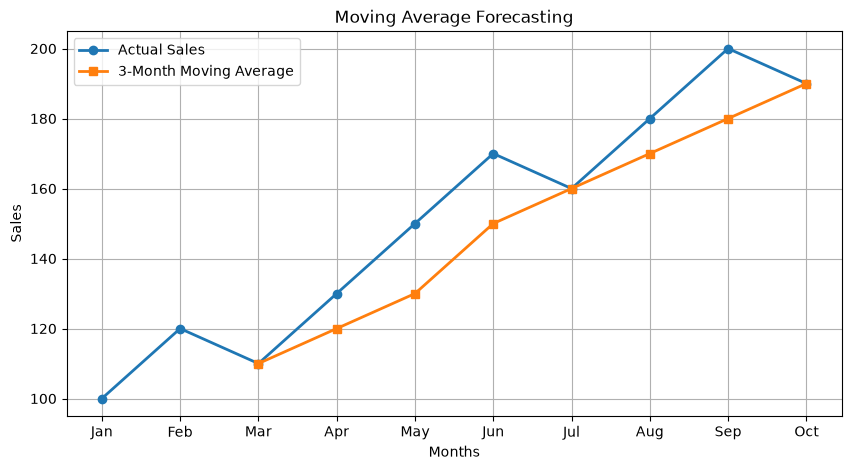

In [23]:
plt.figure(figsize=(10,5))

# Plot original sales
plt.plot(df["Months"],
         df["Sales"],
         marker='o',
         linewidth=2,
         label="Actual Sales")

# Plot moving average
plt.plot(df["Months"],
         df["Moving_Average"],
         marker='s',
         linewidth=2,
         label="3-Month Moving Average")

# Add title
plt.title("Moving Average Forecasting")

# X-axis label
plt.xlabel("Months")

# Y-axis label
plt.ylabel("Sales")

# Show legend
plt.legend()

# Display grid
plt.grid(True)

# Show graph
plt.show()

In [24]:
df

,Months,Sales,Moving_Average
0,Jan,100,NaN
1,Feb,120,NaN
2,Mar,110,110.0
3,Apr,130,120.0
4,May,150,130.0
5,Jun,170,150.0
6,Jul,160,160.0
7,Aug,180,170.0
8,Sep,200,180.0
9,Oct,190,190.0


In [26]:
from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
import numpy as np

evaluation_df=df.dropna()

mae=mean_absolute_error(
    evaluation_df["Sales"],
    evaluation_df["Moving_Average"]
)

mse=mean_squared_error(
    evaluation_df["Sales"],
    evaluation_df["Moving_Average"]
)

rmse=np.sqrt(mse)

mape = mean_absolute_percentage_error(
    evaluation_df["Sales"],
    evaluation_df["Moving_Average"]
)

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("MAPE :", round(mape * 100, 2), "%")

MAE  : 10.0
MSE  : 175.0
RMSE : 13.228756555322953
MAPE : 6.04 %
